In [76]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator
 
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)
 
val_test_datagen = ImageDataGenerator(rescale=1./255)
 
train_data = train_datagen.flow_from_directory(
    'train_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)
 
validation_data = val_test_datagen.flow_from_directory(
    'test_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)
 
test_data = val_test_datagen.flow_from_directory(
    'test_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)          

Found 100 images belonging to 2 classes.
Found 97 images belonging to 2 classes.
Found 97 images belonging to 2 classes.


In [172]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

# Load DenseNet121 with pre-trained ImageNet weights, without the top classification layer
base_model = DenseNet121(input_shape=(500, 500, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze the base model

# Add custom layers on top of the base model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(train_data.num_classes, activation='softmax')(x)

# Define the model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [174]:
history = model.fit(
    train_data,
    epochs=15,
    validation_data=validation_data
)

Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step - accuracy: 0.5149 - loss: 0.7129 - val_accuracy: 0.5361 - val_loss: 0.6891
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.6115 - loss: 0.6429 - val_accuracy: 0.6804 - val_loss: 0.6496
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.7587 - loss: 0.5691 - val_accuracy: 0.6392 - val_loss: 0.6386
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.8675 - loss: 0.4494 - val_accuracy: 0.6598 - val_loss: 0.6278
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8729 - loss: 0.4513 - val_accuracy: 0.6598 - val_loss: 0.6195
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8555 - loss: 0.3980 - val_accuracy: 0.5979 - val_loss: 0.6423
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.9089 - loss: 0.3822 - val_accuracy: 0.6495 - val_loss: 0.6325
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - accuracy: 0.9404 - loss: 0.3517 - val_accuracy: 0.6392 - val_loss:

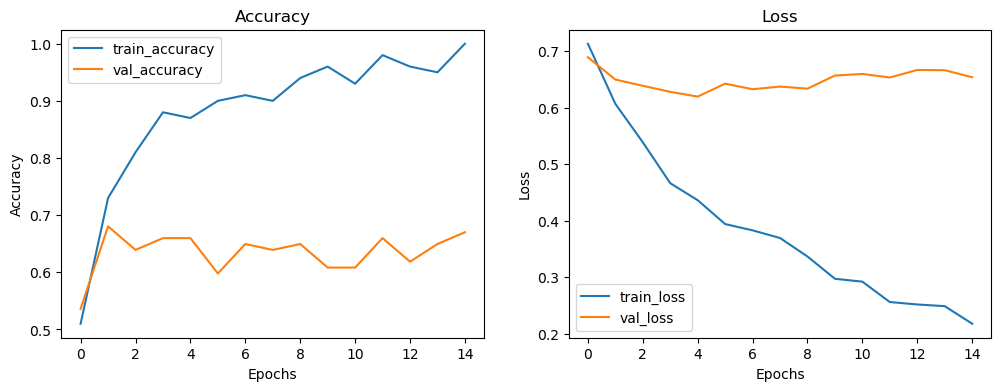

In [175]:
import matplotlib.pyplot as plt
# Plotting training and validation accuracy/loss
plt.figure(figsize=(12, 4))
 
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
 
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
 
plt.show()

In [176]:
test_loss, test_acc = model.evaluate(test_data)
print(f'Test accuracy: {test_acc}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6477 - loss: 0.6568
Test accuracy: 0.6701030731201172


In [177]:
train_loss, train_acc = model.evaluate(train_data)
print(f'Train accuracy: {train_acc}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 936ms/step - accuracy: 0.9723 - loss: 0.2321
Train accuracy: 0.9700000286102295


In [178]:
base_model.trainable = True
 
# Freeze the first few layers
for layer in base_model.layers[:50]:
    layer.trainable = False
 
# Recompile the model with a lower learning rate
model.compile(optimizer=Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])
 
# Continue training
history_fine = model.fit(
    train_data,
    epochs=30,
    validation_data=validation_data)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 61s 4s/step - accuracy: 0.8713 - loss: 0.3683 - val_accuracy: 0.6598 - val_loss: 0.6670
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.8944 - loss: 0.3140 - val_accuracy: 0.6598 - val_loss: 0.6601
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.9088 - loss: 0.2800 - val_accuracy: 0.6392 - val_loss: 0.6766
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.8563 - loss: 0.3154 - val_accuracy: 0.6598 - val_loss: 0.7122
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.8020 - loss: 0.4055 - val_accuracy: 0.6701 - val_loss: 0.7329
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.9108 - loss: 0.2524 - val_accuracy: 0.6598 - val_loss: 0.7206
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.9594 - loss: 0.1614 - val_accuracy: 0.7113 - val_loss: 0.6956
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.9598 - loss: 0.1652 - val_accuracy: 0.6907 - val_loss:

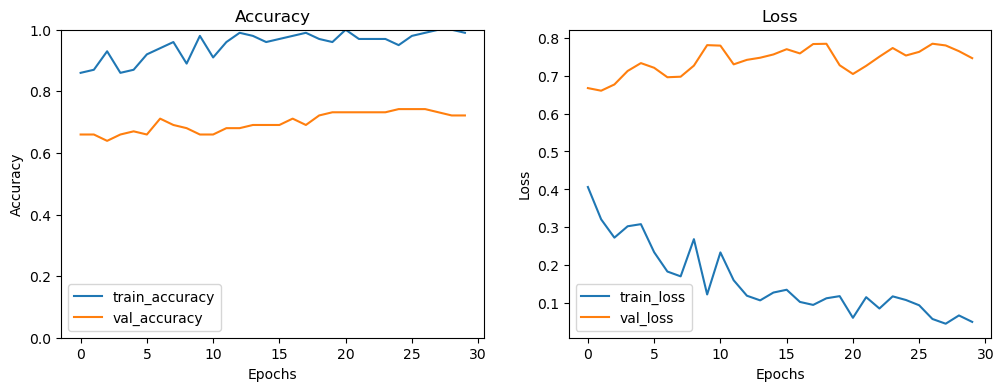

In [184]:
import matplotlib.pyplot as plt
# Plotting training and validation accuracy/loss
plt.figure(figsize=(12, 4))
 
plt.subplot(1, 2, 1)
plt.plot(history_fine.history['accuracy'], label='train_accuracy')
plt.plot(history_fine.history['val_accuracy'], label='val_accuracy')
plt.ylim([0,1])
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
 
plt.subplot(1, 2, 2)
plt.plot(history_fine.history['loss'], label='train_loss')
plt.plot(history_fine.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
 
plt.show()

In [186]:
train_loss, train_acc = model.evaluate(train_data)
print(f'Train accuracy: {train_acc}')

test_loss, test_acc = model.evaluate(test_data)
print(f'Test accuracy: {test_acc}')


13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 939ms/step - accuracy: 1.0000 - loss: 0.0081
Train accuracy: 1.0
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.7273 - loss: 0.7664
Test accuracy: 0.7216494679450989
